In [1]:
! [ -e /content ] && pip install -Uqq fastbook
import fastbook
fastbook.setup_book()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 719.8/719.8 kB 19.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 106.9 MB/s eta 0:00:00
Mounted at /content/gdrive


In [2]:
from fastbook import *
from fastai.vision.widgets import *

To download images with SerpAPI, sign up at SerpAPI for a free account. You will be given a key, which you can copy and enter in a cell as follows:

In [3]:
key = os.environ.get('SERP_API_KEY', '2cfb9e10c029db9d97da5f830f301b459d32beb4f8bc6fefa2b25eff19eecfe4')

In [4]:
search_images_serpapi

<function fastai.vision.utils.search_images_serpapi(term, engine='bing_images', key=None, max_images=150)>

In [5]:
results = search_images_serpapi('ragdoll cat', key=key)
ims = results
len(ims)

131

We've successfully downloaded the URLs of 120+ Ragdoll cats (or, at least, images that SerpAPI Search finds for that search term).

In [6]:
dest = 'images/ragdoll.jpg'
download_url(ims[0], dest)

<div><progress max="1091938" value="1097728"></progress> 100.53% [1097728/1091938 00:00&lt;00:00]</div>

Path('images/ragdoll.jpg')

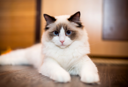

In [7]:
im = Image.open(dest)
im.to_thumb(128,128)

In [8]:
cat_types = 'ragdoll', 'persian', 'british shorthair', 'maine coon'
path = Path('cats')

In [9]:
if not path.exists():
  path.mkdir()
  for cat in cat_types:
    dest = (path/cat)
    dest.mkdir(exist_ok=True)
    results = search_images_serpapi(f"{cat} cat", key=key)
    download_images(dest, urls=results)

Our folder has image files, as we'd expect:

In [10]:
fns = get_image_files(path)
fns

(#486) [Path('cats/persian/ab883cb7-5869-4457-b14c-4e6bb547ee8d.jpg'), Path('cats/persian/5b58512a-4e19-4b5d-8d7a-daf63ac4b087.jpg'), Path('cats/persian/728a232a-169e-4d4f-8562-20e3785ff849.jpg'), Path('cats/persian/176e8f2c-568a-4108-8b6e-cfcaf0fe3a1d.jpeg'), Path('cats/persian/b43ee342-9d8a-44da-8c0c-cc74b62b8bf7.jpeg'), Path('cats/persian/9228ef6b-176d-4459-a6ad-f3b404595892.jpg'), Path('cats/persian/3a8b5169-a78b-4411-9ebd-ffff18f315f7.jpg'), Path('cats/persian/3765c26c-7a0a-46f9-b557-665d6d415804.jpg'), Path('cats/persian/cd32143d-c272-48e1-bdcb-a419e07951cc.jpg'), Path('cats/persian/f227d235-91da-48a5-b248-9c226d56d118.jpg'), Path('cats/persian/af44c9a0-c752-4dc8-b0c4-8c3429c6a294.jpg'), Path('cats/persian/c5237805-d8b2-4b38-bac0-f3d6da7b73ef.jpg'), Path('cats/persian/f6381496-1014-4bbd-b852-e93f0726b704.jpg'), Path('cats/persian/49c917c1-dd47-4e43-a02f-ad675002a6a7.jpg'), Path('cats/persian/08e68437-4b59-4309-8d7e-eba366ed65b8.jpg'), Path('cats/persian/93534174-acc9-4bf6-916c-7e

Often when we download files form the internet, there are a few that are corrupt. Let's check:

In [11]:
failed = verify_images(fns)
failed

[Path('cats/persian/62943ec1-db2d-4b83-a9b1-0760c57b5a28.jpeg'), Path('cats/maine coon/38d022cc-3734-4447-a33e-385d2bbb7d45.jpg'), Path('cats/maine coon/9b691563-a64e-4029-bcd1-a77f59db85f3.jpg'), Path('cats/ragdoll/9a05943f-a890-46d7-8c74-a4fd285e3c68.jpg'), Path('cats/ragdoll/2c43418d-db64-4585-801d-fe1349da4df1.jpg')]

To remove all the failed images, you can use `unlink` on each of them. Note that, like most fastai functions that return a collection, `verify_images` returns an object of type `L`, which includes the `map` method. This calls the passed function on each element of the collection:

In [12]:
failed.map(Path.unlink);

To turn our downloaded data into a `DataLoaders` object we need to tell fastai at least four things:


*   What kinds of data we are working with
*   How to get the list of items
*   How to label these items
*   How to create the validation set

In [13]:
cats = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=Resize(128)
)

`parent_label` is a function provided by fastai that simply gets the name of the folder a file is in. Because we put each of our cat images into folders based on the type of cat, this is going to give us the labels that we need.

In [14]:
dls = cats.dataloaders(path)

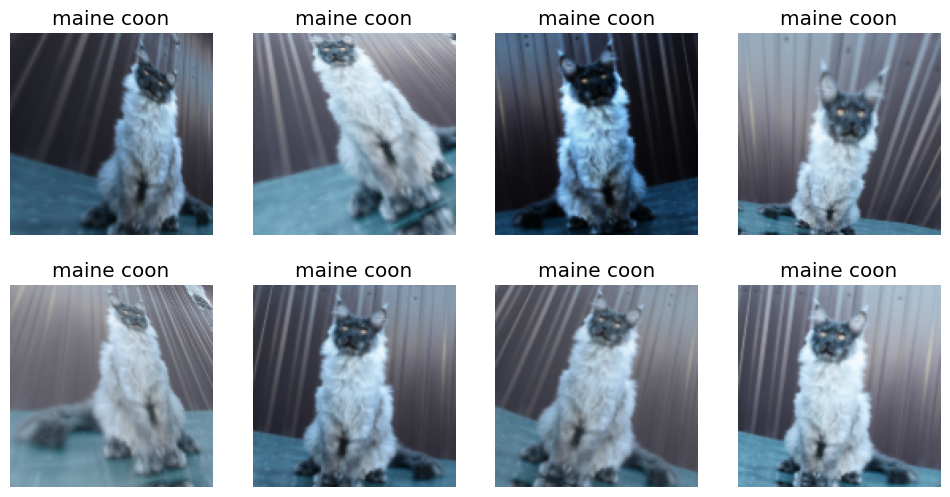

In [15]:
cats = cats.new(item_tfms=Resize(128), batch_tfms=aug_transforms(mult=2))
dls = cats.dataloaders(path)
dls.train.show_batch(max_n=8, nrows=2, unique=True)

Training the model

In [16]:
cats = cats.new(
    item_tfms=RandomResizedCrop(224, min_scale=0.5),
    batch_tfms=aug_transforms()
)
dls = cats.dataloaders(path)

Create our `Learner` and fine-tune it in the usual way:

In [17]:
learn = vision_learner(dls, resnet18, metrics=error_rate)
learn.fine_tune(15)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 184MB/s]


epoch,train_loss,valid_loss,error_rate,time
0,1.889698,0.365309,0.145833,00:23


epoch,train_loss,valid_loss,error_rate,time
0,0.653776,0.289223,0.104167,00:22
1,0.503215,0.257127,0.093750,00:23
2,0.431479,0.255401,0.083333,00:25
3,0.361415,0.267849,0.083333,00:21
4,0.295671,0.228424,0.093750,00:21
5,0.249669,0.194095,0.083333,00:20
6,0.215466,0.217117,0.062500,00:20
7,0.184236,0.211900,0.062500,00:20
8,0.159803,0.240883,0.083333,00:20
9,0.140411,0.237598,0.072917,00:21


Now let's see whether the mistakes the model is making are mainly thinking that grizzlies are teddies (that would be bad for safety!), or that grizzlies are black bears, or something else. To visualize this, we can create a *confusion matrix*:

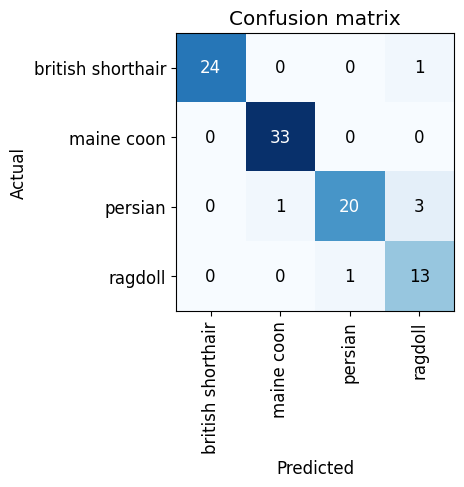

In [18]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

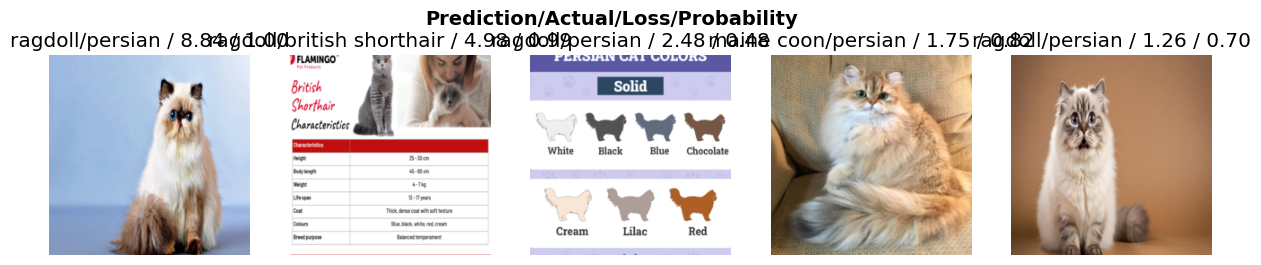

In [19]:
interp.plot_top_losses(5, nrows=1)

fastai includes a handy GUI for data cleaning called `ImageClassifierCleaner` that allows you to choose a category and the training versus validation set and view the highest-loss images (in order), along with menus to allow images to be selected for removal or relabeling:

In [24]:
cleaner = ImageClassifierCleaner(learn)
cleaner

<div><progress max="7" value="1"></progress> 14.29% [1/7 00:03&lt;00:20]</div>

FileNotFoundError: Caught FileNotFoundError in DataLoader worker process 1.
Original Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/worker.py", line 358, in _worker_loop
    data = fetcher.fetch(index)  # type: ignore[possibly-undefined]
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/fetch.py", line 44, in fetch
    data = next(self.dataset_iter)
  File "/usr/local/lib/python3.13/dist-packages/fastai/data/load.py", line 141, in create_batches
    yield from map(self.do_batch, self.chunkify(res))
  File "/usr/local/lib/python3.13/dist-packages/fastcore/basics.py", line 298, in chunked
    res = list(itertools.islice(it, chunk_sz))
  File "/usr/local/lib/python3.13/dist-packages/fastai/data/load.py", line 171, in do_item
    try: return self.after_item(self.create_item(s))
                                ~~~~~~~~~~~~~~~~^^^
  File "/usr/local/lib/python3.13/dist-packages/fastai/data/load.py", line 178, i

In [25]:
for idx in cleaner.delete(): cleaner.fns[idx].unlink()

FileNotFoundError: [Errno 2] No such file or directory: 'cats/british shorthair/d0406442-0ee9-49bb-b5e6-c7f50fb1f106.jpg'

In [ ]:
for idx,cat in cleaner.change(): shutil.move(str(cleaner.fns[idx]), path/cat)

In [27]:
dls = cats.dataloaders(path)

Retrain the model after remove cleaning images.

In [28]:
learn = vision_learner(dls, resnet34, metrics=error_rate)
learn.fine_tune(12)

epoch,train_loss,valid_loss,error_rate,time
0,1.952688,0.466573,0.210526,00:21


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e9d71f4dda0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e9d71f4dda0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

epoch,train_loss,valid_loss,error_rate,time
0,0.693806,0.213235,0.042105,00:22
1,0.503309,0.136748,0.021053,00:20
2,0.393136,0.154686,0.042105,00:21
3,0.327212,0.108807,0.031579,00:20
4,0.261438,0.107620,0.042105,00:22
5,0.225361,0.099257,0.021053,00:19
6,0.193546,0.083375,0.021053,00:20
7,0.168781,0.064114,0.021053,00:20
8,0.147114,0.058624,0.021053,00:20
9,0.128157,0.055730,0.021053,00:22


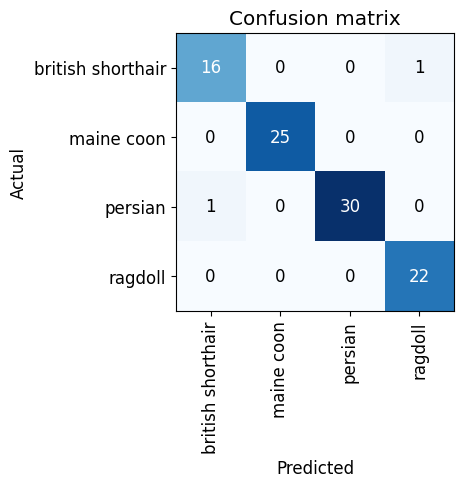

In [29]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

In [30]:
learn.export()

In [31]:
path = Path()
path.ls(file_exts='.pkl')

[Path('export.pkl')]

In [32]:
learn_inf = load_learner(path/'export.pkl')

/usr/local/lib/python3.13/dist-packages/fastai/learner.py:456: UserWarning: load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.
If you only need to load model weights and optimizer state, use the safe `Learner.load` instead.
  warn("load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.\nIf you only need to load model weights and optimizer state, use the safe `Learner.load` instead.")


In [33]:
learn_inf.predict('images/ragdoll.jpg')

('ragdoll',
 tensor(3),
 tensor([4.3300e-06, 3.4741e-08, 7.4815e-09, 1.0000e+00]))

In [34]:
learn_inf.dls.vocab

['british shorthair', 'maine coon', 'persian', 'ragdoll']

Creating a Notebook App from the Model

In [35]:
btn_upload = widgets.FileUpload()
btn_upload

FileUpload(value={}, description='Upload')

In [37]:
img = PILImage.create(btn_upload.data[-1])

In [38]:
out_pl = widgets.Output()
out_pl.clear_output()
with out_pl: display(img.to_thumb(128,128))
out_pl

Output()

Get our predictions

In [39]:
pred,pred_idx,probs = learn_inf.predict(img)

In [40]:
lbl_pred = widgets.Label()
lbl_pred.value = f'Prediction: {pred}; Probability: {probs[pred_idx]:.04f}'
lbl_pred

Label(value='Prediction: maine coon; Probability: 0.9993')

Create a button to do the classification.

In [41]:
btn_run = widgets.Button(description='Classify')
btn_run

Button(description='Classify', style=ButtonStyle())

In [42]:
def on_click_classify(change):
    img = PILImage.create(btn_upload.data[-1])
    out_pl.clear_output()
    with out_pl: display(img.to_thumb(128,128))
    pred,pred_idx,probs = learn_inf.predict(img)
    lbl_pred.value = f'Prediction: {pred}; Probability: {probs[pred_idx]:.04f}'

btn_run.on_click(on_click_classify)

Put them all in a vertical box (VBox) to complete our GUI:

In [43]:
VBox([widgets.Label('Select your cat!'),
      btn_upload, btn_run, out_pl, lbl_pred])

Turning Notebook into a Real App

In [ ]:
# !pip install voila
# !jupyter serverextension enable --sys-prefix voila

In [44]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [46]:
!git clone https://github.com/chphuttipan/cat_classification.git

fatal: destination path 'cat_classification' already exists and is not an empty directory.


In [47]:
!cp "/content/drive/MyDrive/Colab Notebooks/cat-classifier/cat-classification.ipynb"
!cp "/content/drive/MyDrive/Colab Notebooks/cat-classifier/export.pkl"

cp: missing destination file operand after '/content/drive/MyDrive/Colab Notebooks/cat-classifier/cat-classification.ipynb'
Try 'cp --help' for more information.
cp: missing destination file operand after '/content/drive/MyDrive/Colab Notebooks/cat-classifier/export.pkl'
Try 'cp --help' for more information.
